In [1]:

import pandas as pd
import numpy as np

data = {
    "order_id": list(range(1, 21)),
    "customer_name": [
        "Amit", "Riya", "Neha", "Raj", "Priya",
        "Aman", "Karan", "Mira", "Jay", "Tina",
        "Dev", "Sara", "Om", "Diya", "Arjun",
        "Nisha", "Yash", "Isha", "Manav", "Kavya"
    ],
    "restaurant_name": [
        "Spice Hub", "Pizza Point", "Green Bowl", "Burger House",
        "Spice Hub", "Cafe Bean", "Pizza Point", "Green Bowl",
        "Burger House", "Cafe Bean", "Spice Hub", "Pizza Point",
        "Green Bowl", "Burger House", "Cafe Bean", "Spice Hub",
        "Pizza Point", "Green Bowl", "Burger House", "Cafe Bean"
    ],
    "category": [
        "Indian", "Italian", "Healthy", "Fast Food", "Indian",
        "Cafe", "Italian", "Healthy", "Fast Food", "Cafe",
        "Indian", "Italian", "Healthy", "Fast Food", "Cafe",
        "Indian", "Italian", "Healthy", "Fast Food", "Cafe"
    ],
    "delivery_time_mins": [
        25, 30, np.nan, 40, 28, 20, 35, 32, 45, 22,
        27, 31, 29, np.nan, 24, 26, 38, 33, 42, 23
    ],
    "order_value": [
        250, 400, 300, 500, np.nan, 200, 450, 350, 600, 180,
        280, 420, 320, 550, 220, 270, 10000, 340, 580, np.nan
    ],
    "rating": [
        4.5, 4.0, 4.2, np.nan, 4.6, 3.9, 4.1, 4.3, 3.8, 4.4,
        4.7, 4.0, 4.2, 3.7, 4.5, 4.6, np.nan, 4.1, 3.9, 4.3
    ]
}

# Create DataFrame
df = pd.DataFrame(data)

# Introduce one missing categorical value
df.loc[2, "category"] = np.nan

# Add three duplicate rows
df = pd.concat(
    [df, df.iloc[[0, 1, 2]]],
    ignore_index=True
)

# Display the dataset
print(df)

# Check dataset information
print("\nDataset information:")
df.info()

# Count missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check dataset shape
print("\nDataset shape:", df.shape)


    order_id customer_name restaurant_name   category  delivery_time_mins  \
0          1          Amit       Spice Hub     Indian                25.0   
1          2          Riya     Pizza Point    Italian                30.0   
2          3          Neha      Green Bowl        NaN                 NaN   
3          4           Raj    Burger House  Fast Food                40.0   
4          5         Priya       Spice Hub     Indian                28.0   
5          6          Aman       Cafe Bean       Cafe                20.0   
6          7         Karan     Pizza Point    Italian                35.0   
7          8          Mira      Green Bowl    Healthy                32.0   
8          9           Jay    Burger House  Fast Food                45.0   
9         10          Tina       Cafe Bean       Cafe                22.0   
10        11           Dev       Spice Hub     Indian                27.0   
11        12          Sara     Pizza Point    Italian                31.0   

In [6]:
# Question-1

import pandas as pd

df['customer_rating'] = pd.to_numeric(
    df['rating'], errors='coerce'
)

print(df['customer_rating'].dtype)

float64


In [ ]:
# Question - 2

mean_value = np.mean(df['order_value'])
std_value = np.std(df['order_value'])

threshold = mean_value + 1.5 * std_value

mask = df['order_value'] > threshold

high_value_orders = df[mask]

print("High-value orders:")
print(high_value_orders[['order_id', 'restaurant_name', 'order_value']])

print("Number of high-value orders:", len(high_value_orders))
print("Total value of high-value orders:", high_value_orders['order_value'].sum())

High-value orders:
    order_id restaurant_name  order_value
8          9    Burger House        600.0
16        17     Pizza Point        740.0
Number of high-value orders: 2
Total value of high-value orders: 1340.0


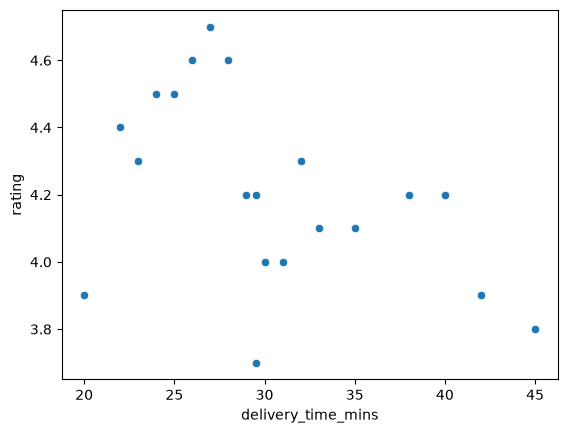

In [ ]:
# Question - 3

import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=df,
    x='delivery_time_mins',
    y='rating'
)
plt.show()

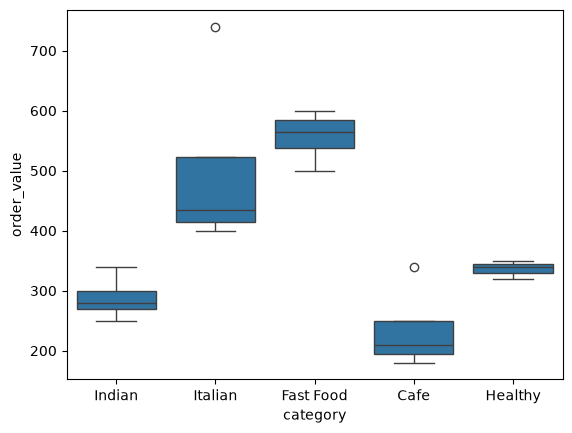

In [15]:
sns.boxplot(
    data=df,
    x='category',
    y='order_value'
)
plt.show()

# Question - 4

I would use a LEFT JOIN to display every restaurant, including restaurants that have not received any orders.

SELECT
    r.name,
    COALESCE(SUM(o.order_value), 0) AS total_revenue
FROM restaurants r
LEFT JOIN orders o
    ON r.restaurant_id = o.restaurant_id
GROUP BY r.restaurant_id, r.name;

Explanation:
- LEFT JOIN returns every row from the left table (restaurants).
- Matching orders are included when available.
- Restaurants without orders still appear, with NULL values for the order columns.
- COALESCE() converts the resulting NULL revenue to zero.


Q5. SQL Window Functions for Ranking Delivery Agents

I would use the RANK() and LAG() window functions.
- RANK() ranks delivery agents based on completed deliveries.
- LAG() retrieves the completed-delivery count of the previous agent in the ranking.

Example:

SELECT
    city,
    agent_name,
    completed_deliveries,
    RANK() OVER (
        PARTITION BY city
        ORDER BY completed_deliveries DESC
    ) AS agent_rank,
    LAG(completed_deliveries) OVER (
        PARTITION BY city
        ORDER BY completed_deliveries DESC
    ) AS previous_agent_deliveries
FROM agent_performance;

Explanation:
PARTITION BY city creates a separate ranking group for each city. Therefore, agents are compared only with other agents in the same city.
Window functions preserve individual rows while calculating rankings and previous-row values. Compared with a GROUP BY and self-join or correlated subquery, they provide a clearer and more maintainable solution.
For the current month's report, the data should first be filtered to completed deliveries within the current month. A unique tie-breaker can also be added to the ORDER BY clause for consistent ordering.

Q6. CTE vs Nested Subquery
Answer:
A CTE (Common Table Expression) is a temporary named result defined using the WITH clause. It makes complex SQL queries easier to read and understand.
Example using a CTE:

WITH top_categories AS ( 
    SELECT category, COUNT(*) AS total_orders
    FROM restaurants r
    JOIN orders o
        ON r.restaurant_id = o.restaurant_id
    GROUP BY category
    ORDER BY total_orders DESC
    LIMIT 5
)
SELECT o.*
FROM orders o
JOIN restaurants r
    ON o.restaurant_id = r.restaurant_id
JOIN top_categories tc
    ON r.category = tc.category;